## Packages Installation

In [ ]:
%uv requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%uv remove pillow
%uv add pillow

Found existing installation: pillow 12.3.0
Uninstalling pillow-12.3.0:
  Successfully uninstalled pillow-12.3.0
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/7.2 MB 5.6 MB/s eta 0:00:02
   ------------- -------------------------- 2.4/7.2 MB 6.1 MB/s eta 0:00:01
   -------------------- ------------------- 3.7/7.2 MB 6.2 MB/s eta 0:00:01
   ----------------------- ---------------- 4.2/7.2 MB 5.5 MB/s eta 0:00:01
   ----------------------------- ---------- 5.2/7.2 MB 5.1 MB/s eta 0:00:01
   ---------------------------------- ----- 6.3/7.2 MB 5.3 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 5.2 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


## Importing Libraries

In [1]:
# Required Libraries
import os
import io
import time
import base64
from pathlib import Path
from getpass import getpass

import fitz
import pandas as pd

from PIL import Image
from IPython.display import display

from groq import Groq

from pinecone import Pinecone, ServerlessSpec

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langchain_groq import ChatGroq
from langchain_pinecone import PineconeVectorStore
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.output_parsers import StrOutputParser

## PDF and Model Configuration

In [3]:

PDF_PATH = Path("Documents/Internship_Report.pdf")

assert PDF_PATH.exists(), (
    "PDF not found. Make sure Internship_Report.pdf "
    "is inside the Documents folder."
)

print("PDF Path: ",PDF_PATH)

PDF Path:  Documents\Internship_Report.pdf


In [34]:
TEXT_MODEL = "openai/gpt-oss-20b"
VISION_MODEL = "qwen/qwen3.8-27b"
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

PINECONE_INDEX_NAME = "internship-report-multimodal-rag"
PINECONE_NAMESPACE = "internship-report"

IMAGE_DIR = Path("internship_report_extracted_images")
IMAGE_DIR.mkdir(exist_ok=True)

print("PDF:", PDF_PATH)
print("Pinecone index:", PINECONE_INDEX_NAME)
print("Pinecone namespace:", PINECONE_NAMESPACE)


PDF: Documents\Internship_Report.pdf
Pinecone index: internship-report-multimodal-rag
Pinecone namespace: internship-report


## API KEYS

In [10]:
from dotenv import load_dotenv

load_dotenv()

print("Groq key loaded:", bool(os.getenv("GROQ_API_KEY")))
print("Pinecone key loaded:", bool(os.getenv("PINECONE_API_KEY")))

if bool(os.getenv("GROQ_API_KEY")) and bool(os.getenv("PINECONE_API_KEY")):
    print("API clients are ready.")
else:
    print("Missing one or more API keys.")


Groq key loaded: True
Pinecone key loaded: True
API clients are ready.


In [11]:
text_llm = ChatGroq(
    model=TEXT_MODEL,
    temperature=0,
)

text_llm


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000251373C15B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002513766C830>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

## Helper : Convert image to base64

In [12]:
# uri -> Uniform Resource Identifier.
def image_to_data_uri(image_path):
    image_path = Path(image_path)

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((1600, 1600))

        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=85)

    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")
    return f"data:image/jpeg;base64,{encoded}"

## Summarize images, charts, and diagrams


We do not embed raw images with the text embedding model.

Instead:

```text
Image / Chart
     ↓
Vision model
     ↓
Text summary
     ↓
Embedding
     ↓
Pinecone
```

We still keep the original image path so the final answer can use the real visual.

In [13]:
def summarize_visual(image_path, page_number):
    image_data = image_to_data_uri(image_path)

    prompt = f"""
This visual was extracted from page {page_number} of the Internship Report.

Analyze the visual in the context of the internship, company, project, technical work, or business information presented in the report.

Provide a concise and factual description of the information visible.

For charts or graphs:
- Mention important values, percentages, categories, and dates.
- Identify the highest and lowest values when clearly visible.
- Explain the main trend or comparison.

For tables:
- Summarize the important values, categories, totals, and comparisons.

For diagrams or flowcharts:
- Identify the major components.
- Explain the process, flow, or relationships between components.

For technical or system diagrams:
- Identify important technologies, modules, inputs, outputs, and connections.

For normal images:
- Describe only the useful factual information relevant to the internship or project.

Do not invent or assume information that is not visible.
Keep the description concise and factual.
"""

    response = groq_client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": image_data},
                    },
                ],
            }
        ],
        temperature=0,
        max_completion_tokens=500,
    )

    return response.choices[0].message.content.strip()

In [15]:
import os
from dotenv import load_dotenv
from groq import Groq

load_dotenv()

GROQ_API_KEY = os.getenv("GROQ_API_KEY")

if not GROQ_API_KEY:
    raise ValueError(
        "GROQ_API_KEY not found. Check your .env file."
    )

groq_client = Groq(api_key=GROQ_API_KEY)

print("Groq client initialized successfully.")

Groq client initialized successfully.


## Extract text, tables, and visuals from the PDF

In [17]:


def extract_multimodal_documents(pdf_path):
    pdf = fitz.open(str(pdf_path))

    documents = []
    extracted_xrefs = set()

    for page_index in range(len(pdf)):
        page = pdf[page_index]
        page_number = page_index + 1

        print(f"Processing page {page_number}...")

        # -------------------------------------------------
        # 1. TEXT
        # -------------------------------------------------
        text = page.get_text("text").strip()

        if text:
            documents.append(
                Document(
                    page_content=text,
                    metadata={
                        "page": page_number,
                        "modality": "text",
                        "source": pdf_path.name,
                    },
                )
            )

        # -------------------------------------------------
        # 2. TABLES
        # -------------------------------------------------
        try:
            tables = page.find_tables().tables

            for table_number, table in enumerate(tables, start=1):
                df = table.to_pandas()

                if not df.empty:
                    table_text = df.to_markdown(index=False)

                    documents.append(
                        Document(
                            page_content=table_text,
                            metadata={
                                "page": page_number,
                                "modality": "table",
                                "table_number": table_number,
                                "source": pdf_path.name,
                            },
                        )
                    )

        except Exception as error:
            print("Table extraction warning:", error)

        # -------------------------------------------------
        # 3. IMAGES / CHARTS / DIAGRAMS
        # -------------------------------------------------
        for image_number, image_info in enumerate(
            page.get_images(full=True),
            start=1,
        ):
            xref = image_info[0]

            # Do not process an identical embedded image twice.
            if xref in extracted_xrefs:
                continue

            extracted_xrefs.add(xref)

            image_data = pdf.extract_image(xref)

            image_bytes = image_data["image"]
            image_extension = image_data["ext"]

            # Get image dimensions
            image_width = image_data["width"]
            image_height = image_data["height"]

            # Skip images that are too small for the vision model
            if image_width < 32 or image_height < 32:
                print(
                    f"Skipping tiny image on page {page_number}: "
                    f"{image_width}x{image_height}"
                )
                continue

            image_path = (
                IMAGE_DIR
                / f"page_{page_number}_image_{image_number}.{image_extension}"
            )

            image_path.write_bytes(image_bytes)

            try:
                summary = summarize_visual(
                    image_path=image_path,
                    page_number=page_number,
                )

                documents.append(
                    Document(
                        page_content=summary,
                        metadata={
                            "page": page_number,
                            "modality": "visual",
                            "image_path": str(image_path),
                            "source": pdf_path.name,
                        },
                    )
                )

            except Exception as error:
                print(
                    f"Vision warning on page {page_number}:",
                    error,
                )

    pdf.close()
    return documents


documents = extract_multimodal_documents(PDF_PATH)

print()
print("Total LangChain documents:", len(documents))



Processing page 1...
Processing page 2...
Processing page 3...
Processing page 4...
Processing page 5...
Processing page 6...
Processing page 7...
Processing page 8...
Processing page 9...
Processing page 10...
Processing page 11...
Skipping tiny image on page 11: 17x32
Skipping tiny image on page 11: 552x5
Processing page 12...
Processing page 13...
Skipping tiny image on page 13: 552x5
Processing page 14...
Processing page 15...
Processing page 16...
Skipping tiny image on page 16: 552x5
Processing page 17...
Processing page 18...
Processing page 19...
Processing page 20...
Processing page 21...
Skipping tiny image on page 21: 552x5
Processing page 22...
Processing page 23...
Processing page 24...
Processing page 25...
Processing page 26...
Processing page 27...
Processing page 28...
Skipping tiny image on page 28: 552x5
Processing page 29...
Processing page 30...
Processing page 31...
Processing page 32...
Processing page 33...
Processing page 34...
Processing page 35...

Total Lang

In [18]:
documents

[Document(metadata={'page': 1, 'modality': 'visual', 'image_path': 'internship_report_extracted_images\\page_1_image_1.jpeg', 'source': 'Internship_Report.pdf'}, page_content='Based on the visual provided, here is a concise and factual description:\n\n**Image Description:**\nThe image displays the official logo of **Guru Jambheshwar University of Science & Technology, Hisar**. The logo is presented in two instances: a full, upright version at the top and a partial, tilted version at the bottom.\n\n**Key Visual Elements:**\n*   **Shape:** The logo is contained within a green pentagon.\n*   **Central Emblem:** A circular seal features a stylized tree with green and yellow leaves, set against a blue background with white clouds and an orange sun/gear motif.\n*   **Text (English):** The name "GURU JAMBHESHWAR UNIVERSITY OF SCIENCE & TECHNOLOGY" encircles the central emblem, with "HISAR" located at the bottom of the circle.\n*   **Text (Sanskrit/Hindi):** The motto "ज्ञानं विज्ञानं सहितम्" 

In [28]:
documents[22].page_content.splitlines()

['Based on the visual provided from page 18 of the Internship Report, here is the factual description:',
 '',
 '**Chart Type:** Bar Chart',
 '**Title:** Most notable confusion pairs — Bidirectional GRU',
 '',
 '**Data Points:**',
 'The chart displays two specific categories of misclassification for a Bidirectional GRU model, measured by the "Number of misclassified examples" on the y-axis.',
 '',
 '1.  **Joy $\\rightarrow$ Love**',
 '    *   **Description:** This category represents instances where the true emotion was "Joy" but the model predicted "Love."',
 '    *   **Value:** **46**',
 '    *   **Observation:** This is the highest value shown in the chart, indicating it is the most frequent confusion pair.',
 '',
 '2.  **Fear $\\rightarrow$ Surprise**',
 '    *   **Description:** This category represents instances where the true emotion was "Fear" but the model predicted "Surprise."',
 '    *   **Value:** **22**',
 '    *   **Observation:** This is the lower value compared to the fi

## Inspect extracted content

In [29]:
rows = []

for doc in documents:
    rows.append(
        {
            "page": doc.metadata["page"],
            "modality": doc.metadata["modality"],
            "preview": doc.page_content[:140].replace("\n", " "),
        }
    )

summary_df = pd.DataFrame(rows)

display(summary_df)

print("Documents by modality:")
display(summary_df["modality"].value_counts())

,page,modality,preview
0,1,visual,"Based on the visual provided, here is a concis..."
1,2,text,"DECLARATION I, Ravi, 240252850019, certif..."
2,3,text,INTERNSHIP CERTIFICATE ii
3,3,visual,"Based on the visual provided, here is the fact..."
4,4,text,ACKNOWLEDGEMENT I would like to express my si...
...,...,...,...
56,31,visual,"Based on the visual provided, here is a concis..."
57,32,text,CHAPTER 6 ...
58,33,text,CHAPTER 7 ...
59,34,text,7.3 How This Internship Connects to My Degree ...


Documents by modality:


modality
text      34
visual    14
table     13
Name: count, dtype: int64

## Create embeddings

In [30]:
embeddings = HuggingFaceEmbeddings(
    model_name=EMBEDDING_MODEL,
    encode_kwargs={"normalize_embeddings": True},
)

# Detect the exact vector dimension automatically.
EMBEDDING_DIMENSION = len(
    embeddings.embed_query("dimension check")
)

print("Embedding model:", EMBEDDING_MODEL)
print("Embedding dimension:", EMBEDDING_DIMENSION)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384


Create the Pinecone serverless index

In [35]:
pc = Pinecone(
    api_key=os.environ["PINECONE_API_KEY"]
)

if not pc.has_index(PINECONE_INDEX_NAME):
    print("Creating Pinecone index...")

    pc.create_index(
        name=PINECONE_INDEX_NAME,
        dimension=EMBEDDING_DIMENSION,
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1",
        ),
    )

    # Wait until Pinecone reports that the index is ready.
    while not pc.describe_index(PINECONE_INDEX_NAME).status["ready"]:
        print("Waiting for Pinecone index...")
        time.sleep(2)

    print("Pinecone index created.")
else:
    print("Pinecone index already exists.")

index = pc.Index(PINECONE_INDEX_NAME)

print("Connected to:", PINECONE_INDEX_NAME)

Creating Pinecone index...
Pinecone index created.
Connected to: internship-report-multimodal-rag


## Clean the demo namespace

In [37]:
try:
    index.delete(
        delete_all=True,
        namespace=PINECONE_NAMESPACE,
    )
    print("Cleared namespace:", PINECONE_NAMESPACE)

except Exception as error:
    print("Namespace is empty or does not exist. Continuing...")

Namespace is empty or does not exist. Continuing...


## Store LangChain documents in Pinecone

Now the vector database step is:

```text
LangChain Documents
        ↓
Hugging Face Embeddings
        ↓
PineconeVectorStore
        ↓
Pinecone
```

In [80]:
vector_store = PineconeVectorStore(
    index_name=PINECONE_INDEX_NAME,
    embedding=embeddings,
    namespace=PINECONE_NAMESPACE,
)

vector_store.add_documents(documents)

print("Documents uploaded to Pinecone.")

Documents uploaded to Pinecone.


## Create the Pinecone retriever

In [82]:
retriever = vector_store.as_retriever(
    search_kwargs={"k": 5}
)

print("Retriever is ready.")

Retriever is ready.


## Test Pinecone retrieval

In [84]:
query = "Explain the company SSH Softech Solutions."

retrieved_docs = retriever.invoke(query)

for i, doc in enumerate(retrieved_docs, start=1):
    print("=" * 80)
    print(
        f"Result {i} | "
        f"Page: {doc.metadata.get('page')} | "
        f"Type: {doc.metadata.get('modality')}"
    )
    print(doc.page_content[:1000])
    print()

Result 1 | Page: 11.0 | Type: text
CHAPTER 1 
COMPANY 
PROFILE 
 
 
 
1.1  Executive Summary 
SSH Softech Solutions is a technology company focused on developing intelligent 
and scalable software solutions. The company works in areas such as Artificial 
Intelligence, Generative AI, custom AI chatbots, Retrieval-Augmented Generation 
(RAG) systems, web and mobile application development, and custom software 
solutions. Its work focuses on building practical technology solutions for industries 
including healthcare, education, real estate, logistics, travel, and e-commerce. 
The company operates in the IT Services and IT Consulting sector, with expertise in 
application development, web development, data engineering, Artificial Intelligence, 
Machine Learning, cybersecurity, and Generative AI. SSH Softtech Solution Private 
Limited was incorporated in 2024. 
I completed my Machine Learning Internship at SSH Softech Solutions from 28 
June 2026 to 28 July 2026. The internship provided me

##  Create the LangChain text RAG chain

For text and tables:

```text
Question
   ↓
Pinecone Retriever
   ↓
Relevant Context
   ↓
Prompt
   ↓
Text LLM
   ↓
Answer
```

In [46]:
rag_prompt = ChatPromptTemplate.from_template(
    """
You are a helpful assistant answering questions about the Internship Report.

Use ONLY the retrieved context below.

Do not use outside knowledge.

If the answer is not available in the retrieved context, say:
"I could not find that information in the report."

Mention the relevant page number when possible.

CONTEXT:
{context}

QUESTION:
{question}

ANSWER:
"""
)

text_rag_chain = (
    rag_prompt
    | text_llm
    | StrOutputParser()
)

print("Text RAG chain is ready.")

Text RAG chain is ready.


## Format retrieved context

In [47]:
def format_context(retrieved_docs):
    parts = []

    for doc in retrieved_docs:
        page = doc.metadata.get("page")
        modality = doc.metadata.get("modality")

        parts.append(
            f"[Page {page} | {modality.upper()}]\n"
            f"{doc.page_content}"
        )

    return "\n\n".join(parts)


## Vision answer helper

If Pinecone retrieves visual evidence:

```text
Pinecone retrieves visual summary
            ↓
Read image_path from metadata
            ↓
Load the original image
            ↓
Question + context + image
            ↓
Vision model
```

In [71]:
def answer_with_vision(question, context, image_paths):

    image_paths = image_paths[:3]
    context = context[:8000]

    content = [
        {
            "type": "text",
            "text": f"""
You are answering questions about the Internship Report.

Use ONLY the retrieved context and the attached retrieved visuals.

Do not use outside knowledge.

RETRIEVED CONTEXT:
{context}

QUESTION:
{question}

Instructions:
- Answer factually.
- Do not invent information.
- Use the attached visuals when relevant.
- Mention page numbers when possible.
- If the information is missing, say:
  "I could not find that information in the report."
""",
        }
    ]

    for image_path in image_paths:
        content.append(
            {
                "type": "image_url",
                "image_url": {
                    "url": image_to_data_uri(image_path)
                },
            }
        )

    response = groq_client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {
                "role": "user",
                "content": content,
            }
        ],
        temperature=0,
        max_completion_tokens=900,
    )

    return response.choices[0].message.content.strip()

## Complete Multimodal RAG function

This is the complete application:

```text
Question
   ↓
Pinecone Retriever
   ↓
Top 5 documents
   ↓
Any visual?
   ├── No  → Text RAG chain
   └── Yes → Vision LLM + retrieved images
   ↓
Final answer
```

In [56]:
def ask_rag(question, show_sources=True, show_images=False):

    # 1. Retrieve from Pinecone
    retrieved_docs = retriever.invoke(question)

    # 2. Create context
    context = format_context(retrieved_docs)

    # 3. Check whether Pinecone returned visuals
    image_paths = []

    for doc in retrieved_docs:
        if doc.metadata.get("modality") == "visual":
            image_path = doc.metadata.get("image_path")

            if image_path and Path(image_path).exists():
                image_paths.append(image_path)

    # 4. Generate the answer
    if image_paths:
        answer = answer_with_vision(
            question=question,
            context=context,
            image_paths=image_paths,
        )
    else:
        answer = text_rag_chain.invoke(
            {
                "context": context,
                "question": question,
            }
        )

    print("\nQUESTION:")
    print(question)

    print("\nANSWER:")
    print(answer)

    if show_sources:
        print("\nPINECONE RETRIEVED SOURCES:")

        for i, doc in enumerate(retrieved_docs, start=1):
            print(
                f"{i}. Page {doc.metadata.get('page')} "
                f"| {doc.metadata.get('modality')}"
            )

    if show_images and image_paths:
        print("\nRETRIEVED VISUALS:")

        for image_path in image_paths:
            display(Image.open(image_path))

    return {
        "answer": answer,
        "documents": retrieved_docs,
        "image_paths": image_paths,
    }

## Test -> Company

In [50]:
ask_rag(
    "What is the name of the company where I completed my internship?"
)


QUESTION:
What is the name of the company where I completed my internship?

ANSWER:
The internship was completed at **SSH Softech Solutions** (SSH Softech Solution Private Limited).  
*Source: Page 11.0*

PINECONE RETRIEVED SOURCES:
1. Page 8.0 | text
2. Page 3.0 | text
3. Page 2.0 | text
4. Page 16.0 | text
5. Page 15.0 | text
6. Page 11.0 | text
7. Page 4.0 | text
8. Page 20.0 | text
9. Page 12.0 | table
10. Page 13.0 | text


{'answer': 'The internship was completed at **SSH Softech Solutions** (SSH Softech Solution Private Limited).  \n*Source: Page\u202f11.0*',
 'documents': [Document(id='3bd48fbe-f652-44bf-937c-019c843c54f9', metadata={'modality': 'text', 'page': 8.0, 'source': 'Internship_Report.pdf'}, page_content='LIST OF CONTENTS \nDeclaration \nInternship Certificate \nAcknowledgement \nList of Figures \nList of Tables \nList of Abbreviations \ni \nii \niii \niv \nv \nvi \nChapter No. \nTitle \nPage No. \nChapter 1 \nCompany Profile \n1-2 \n1.1 Executive Summary \n1 \n1.1.1 Company Vision \n1 \n1.1.2 Company Mission \n1 \n     1.1.3 Company Principles \n1 \n1.2 Scope of Work \n2 \n1.3 Relevance to Data Science Internship \n2 \n1.4 Company Overview \n2 \nChapter 2 \nIntroduction \n3-5 \n2.1 Overview of the Internship \n3 \n2.2 Roles and Responsibilities \n3 \n2.3 Tools and Technologies Used \n4 \n2.4 Skills and Learning Outcomes \n5 \n \nvii'),
  Document(id='adae91e4-e4c2-445e-a32c-65a7c0d1ee3e', me

## Test —> Table question

In [60]:
answer = ask_rag(
    """
    What were the test accuracies of the different models
    compared in the Emotion Prediction project?
    """
)

answer


QUESTION:

    What were the test accuracies of the different models
    compared in the Emotion Prediction project?
    

ANSWER:
Based on the retrieved context, the specific test accuracy percentages for the four models (SimpleRNN, LSTM, GRU, and Bidirectional GRU) are not explicitly stated in the provided text.

The report mentions on **Page 22.0** that "The final test results are presented in Table 4.3" and refers to **Figure 4.3.2** ("Test accuracy comparison across the four models") on **Page 13** (as listed in the List of Figures on **Page 5.0**). However, the content of Table 4.3 and Figure 4.3.2 is not included in the retrieved context.

The only performance data provided is the confusion matrix for the **Bidirectional GRU** model on the test set (shown in the attached visual and described on **Page 25.0**). From this matrix, we can calculate the total correct predictions for the Bidirectional GRU:
*   Sadness: 553
*   Joy: 633
*   Love: 143
*   Anger: 257
*   Fear: 186
*   S

{'answer': 'Based on the retrieved context, the specific test accuracy percentages for the four models (SimpleRNN, LSTM, GRU, and Bidirectional GRU) are not explicitly stated in the provided text.\n\nThe report mentions on **Page 22.0** that "The final test results are presented in Table 4.3" and refers to **Figure 4.3.2** ("Test accuracy comparison across the four models") on **Page 13** (as listed in the List of Figures on **Page 5.0**). However, the content of Table 4.3 and Figure 4.3.2 is not included in the retrieved context.\n\nThe only performance data provided is the confusion matrix for the **Bidirectional GRU** model on the test set (shown in the attached visual and described on **Page 25.0**). From this matrix, we can calculate the total correct predictions for the Bidirectional GRU:\n*   Sadness: 553\n*   Joy: 633\n*   Love: 143\n*   Anger: 257\n*   Fear: 186\n*   Surprise: 62\n\nTotal correct predictions = 553 + 633 + 143 + 257 + 186 + 62 = **1,834**.\n\nGiven that the tes

## Test3 -> Projects Overview

In [51]:
ask_rag(
    """
    What are the two main projects described in my internship report,
    and what was the main result of each project?
    """
)


QUESTION:

    What are the two main projects described in my internship report,
    and what was the main result of each project?
    

ANSWER:
**Main projects**

| Project | Main result (what the project achieved) | Page reference |
|---------|----------------------------------------|----------------|
| **Emotion Classification System** | The system was able to analyse a sentence and predict the emotion expressed in it (six‑class classification). | Chapter 2, 2.1 (page 13.0) |
| **Content‑Based Movie Recommendation System** | The system was able to recommend movies that are similar to a given movie by comparing their content and features. | Chapter 2, 2.1 (page 13.0) |

These two projects are the core of the internship report, and the described results are the primary outcomes of each work‑stream.

PINECONE RETRIEVED SOURCES:
1. Page 8.0 | text
2. Page 16.0 | text
3. Page 34.0 | text
4. Page 13.0 | text
5. Page 2.0 | text
6. Page 20.0 | text
7. Page 3.0 | text
8. Page 10.0 | text
9.

{'answer': '**Main projects**\n\n| Project | Main result (what the project achieved) | Page reference |\n|---------|----------------------------------------|----------------|\n| **Emotion Classification System** | The system was able to analyse a sentence and predict the emotion expressed in it (six‑class classification). | Chapter\u202f2,\u202f2.1 (page\u202f13.0) |\n| **Content‑Based Movie Recommendation System** | The system was able to recommend movies that are similar to a given movie by comparing their content and features. | Chapter\u202f2,\u202f2.1 (page\u202f13.0) |\n\nThese two projects are the core of the internship report, and the described results are the primary outcomes of each work‑stream.',
 'documents': [Document(id='3bd48fbe-f652-44bf-937c-019c843c54f9', metadata={'modality': 'text', 'page': 8.0, 'source': 'Internship_Report.pdf'}, page_content='LIST OF CONTENTS \nDeclaration \nInternship Certificate \nAcknowledgement \nList of Figures \nList of Tables \nList of Abbr

## Test -> Project 2

In [61]:
answer = ask_rag(
    """
    What techniques were used in the content-based movie
    recommendation system?
    """
)
answer


QUESTION:

    What techniques were used in the content-based movie
    recommendation system?
    

ANSWER:
Based on the retrieved context, the following techniques were used in the content-based movie recommendation system (CineMatch):

*   **Feature Engineering (Page 30):** The system combined the movie's overview, genre names, and tagline into a single field called "tags."
*   **NLP Preprocessing (Page 30):** A standard NLP pipeline was applied to the "tags" field, which included:
    *   Converting text to lowercase.
    *   Removing punctuation.
    *   Eliminating common English stop words using NLTK.
    *   Applying WordNet lemmatization to reduce words to their basic forms.
*   **TF-IDF Vectorization (Page 30):** The cleaned text was vectorized using TF-IDF with the following parameters:
    *   Maximum of 50,000 features.
    *   Unigrams and bigrams (`ngram_range = (1, 2)`).
    *   English stop-word removal.
*   **Cosine Similarity (Page 30):** Recommendations were genera

{'answer': 'Based on the retrieved context, the following techniques were used in the content-based movie recommendation system (CineMatch):\n\n*   **Feature Engineering (Page 30):** The system combined the movie\'s overview, genre names, and tagline into a single field called "tags."\n*   **NLP Preprocessing (Page 30):** A standard NLP pipeline was applied to the "tags" field, which included:\n    *   Converting text to lowercase.\n    *   Removing punctuation.\n    *   Eliminating common English stop words using NLTK.\n    *   Applying WordNet lemmatization to reduce words to their basic forms.\n*   **TF-IDF Vectorization (Page 30):** The cleaned text was vectorized using TF-IDF with the following parameters:\n    *   Maximum of 50,000 features.\n    *   Unigrams and bigrams (`ngram_range = (1, 2)`).\n    *   English stop-word removal.\n*   **Cosine Similarity (Page 30):** Recommendations were generated by computing the cosine similarity between a query film\'s TF-IDF vector and ever

## Test -> Overall internship summary

In [62]:
ask_rag(
    """
Give me a short summary of my internship.
Include:
1. company name,
2. internship role and duration,
3. two main projects,
4. major technologies used.
"""
)


QUESTION:

Give me a short summary of my internship.
Include:
1. company name,
2. internship role and duration,
3. two main projects,
4. major technologies used.


ANSWER:
**Short Summary of Your Internship**

| Item | Details | Page |
|------|---------|------|
| **Company** | SSH Softech Solutions | 13.0 |
| **Role & Duration** | Machine Learning Intern (28 June 2026 – 28 July 2026) | 13.0 |
| **Main Projects** | 1. Emotion Classification System (Emotion Prediction)  <br>2. Content‑Based Movie Recommendation System | 13.0 |
| **Major Technologies** | Jupyter Notebook, FastAPI, Git, NLTK, WordNet, TF‑IDF, Hugging Face dataset, Kaggle dataset, and ML/DL models (SimpleRNN, LSTM, GRU, Bidirectional GRU) | 16.0 |

This internship at SSH Softech Solutions gave you hands‑on experience in end‑to‑end machine‑learning workflows, from data acquisition and preprocessing to model training, evaluation, and deployment.

PINECONE RETRIEVED SOURCES:
1. Page 8.0 | text
2. Page 16.0 | text
3. Page 34.0

{'answer': '**Short Summary of Your Internship**\n\n| Item | Details | Page |\n|------|---------|------|\n| **Company** | SSH Softech Solutions | 13.0 |\n| **Role & Duration** | Machine Learning Intern (28\u202fJune\u202f2026\u202f–\u202f28\u202fJuly\u202f2026) | 13.0 |\n| **Main Projects** | 1. Emotion Classification System (Emotion Prediction)  <br>2. Content‑Based Movie Recommendation System | 13.0 |\n| **Major Technologies** | Jupyter Notebook, FastAPI, Git, NLTK, WordNet, TF‑IDF, Hugging Face dataset, Kaggle dataset, and ML/DL models (SimpleRNN, LSTM, GRU, Bidirectional GRU) | 16.0 |\n\nThis internship at SSH Softech Solutions gave you hands‑on experience in end‑to‑end machine‑learning workflows, from data acquisition and preprocessing to model training, evaluation, and deployment.',
 'documents': [Document(id='3bd48fbe-f652-44bf-937c-019c843c54f9', metadata={'modality': 'text', 'page': 8.0, 'source': 'Internship_Report.pdf'}, page_content='LIST OF CONTENTS \nDeclaration \nInterns

## Test -> Dataset Analysis with Image


QUESTION:

    According to the movie dataset analysis, what were the major
    missing-value issues and what does the dataset visualization show?
    

ANSWER:
Based on the retrieved context and visuals, here are the major missing-value issues and what the visualization shows:

**Major Missing-Value Issues (Page 28.0)**
According to the dataset cleaning summary (Table 5.2.1), the major missing-value issues in the movie dataset were:
*   **Tagline:** Approximately 25,045 rows had missing taglines.
*   **Overview:** 954 rows had missing overviews.
*   **Title:** 6 rows were missing a title.

**Dataset Visualization (Page 29.0)**
The visualization (Figure 5.2.1) is a vertical bar chart that displays the "Missing Value Count" for the three fields. It shows a significant disparity in data completeness:
*   The **Tagline** field has the highest count of missing values at **25,045** (represented by a tall orange bar).
*   The **Overview** field has a moderate count of **954** missing values

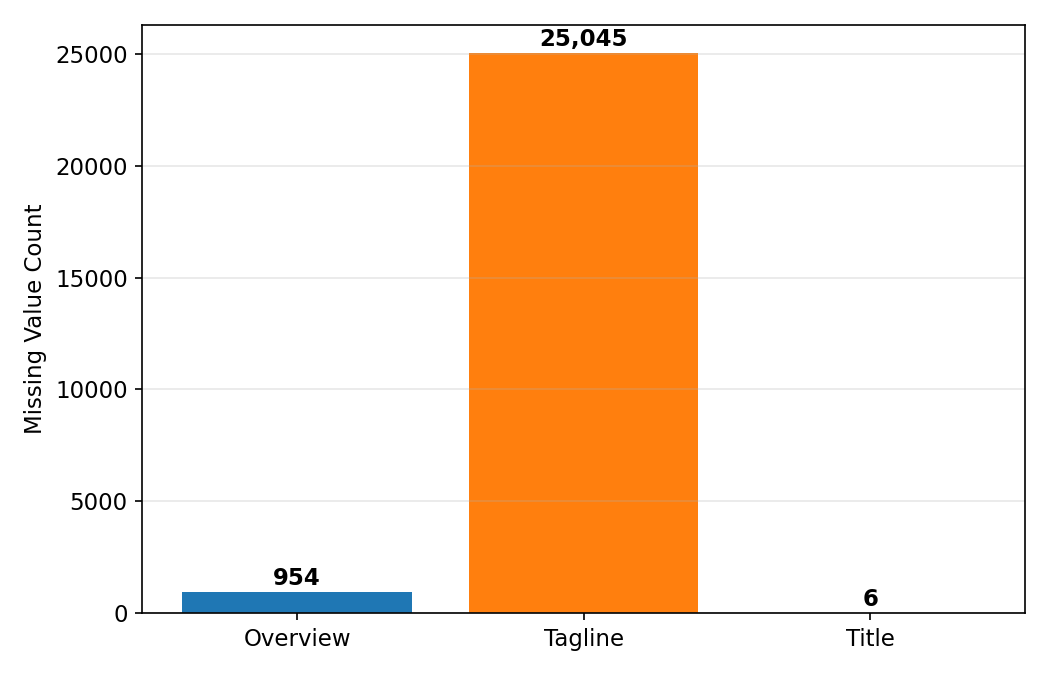

{'answer': 'Based on the retrieved context and visuals, here are the major missing-value issues and what the visualization shows:\n\n**Major Missing-Value Issues (Page 28.0)**\nAccording to the dataset cleaning summary (Table 5.2.1), the major missing-value issues in the movie dataset were:\n*   **Tagline:** Approximately 25,045 rows had missing taglines.\n*   **Overview:** 954 rows had missing overviews.\n*   **Title:** 6 rows were missing a title.\n\n**Dataset Visualization (Page 29.0)**\nThe visualization (Figure 5.2.1) is a vertical bar chart that displays the "Missing Value Count" for the three fields. It shows a significant disparity in data completeness:\n*   The **Tagline** field has the highest count of missing values at **25,045** (represented by a tall orange bar).\n*   The **Overview** field has a moderate count of **954** missing values (represented by a blue bar).\n*   The **Title** field has the lowest count at **6** (represented by a negligible bar height).',
 'document

In [72]:
ask_rag(
    """
    According to the movie dataset analysis, what were the major
    missing-value issues and what does the dataset visualization show?
    """,
    show_images=True,
)